# Week 1 — Environment setup and sensor-array sanity check
    **Donovan Marshall · DEV.BAFAD290.01**

    This notebook uses the course's permitted local execution option: Python in
    Ubuntu/WSL on CPU. It does not claim a Google Colab runtime or Drive mount.
    The personal repository is an existing fork of the faculty starter repository.

    Sources: [Week 1 guide](https://uncfsu.instructure.com/courses/53036/files/10588689?wrap=1) and
    [optional local setup guide](https://uncfsu.instructure.com/courses/53036/files/10599821?wrap=1).


## Environment verification
Verify the packages named in the Week 1 setup guide.


In [1]:
import sys
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
import torch

print('BAFAD — Local environment verification')
print(f'Python: {sys.version.split()[0]}')
print(f'NumPy: {np.__version__}')
print(f'Matplotlib: {matplotlib.__version__}')
print(f'PyTorch: {torch.__version__}')
print(f'GPU available: {torch.cuda.is_available()}')
print('CPU execution is permitted by the course setup guide.')
print('All Week 1 required imports passed.')


BAFAD — Local environment verification
Python: 3.12.3
NumPy: 1.26.4
Matplotlib: 3.11.2
PyTorch: 2.14.1+cpu
GPU available: False
CPU execution is permitted by the course setup guide.
All Week 1 required imports passed.


## Reproducible three-sensor stream
Generate 200 samples, verify the shape, and save the plot.


Sensor stream shape: (200, 3)
Value range: [-1.101, 1.093]


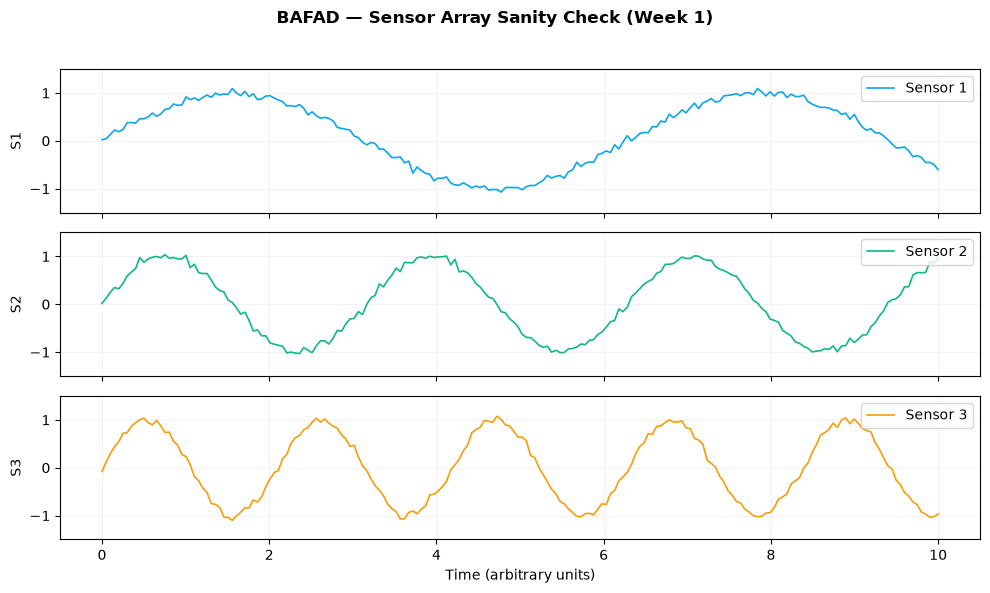

Sanity check passed — environment ready for the current exercises.


In [2]:
np.random.seed(42)
t = np.linspace(0, 10, 200)
sensor_stream = np.stack(
    [np.sin(t * (i + 1)) + np.random.normal(0, 0.05, len(t))
     for i in range(3)], axis=1
)
print(f'Sensor stream shape: {sensor_stream.shape}')
print(f'Value range: [{sensor_stream.min():.3f}, {sensor_stream.max():.3f}]')
assert sensor_stream.shape == (200, 3)
assert np.isfinite(sensor_stream).all()

fig, axes = plt.subplots(3, 1, figsize=(10, 6), sharex=True)
for i, (ax, color) in enumerate(zip(axes, ['#0EA5E9', '#10B981', '#F59E0B'])):
    ax.plot(t, sensor_stream[:, i], color=color, linewidth=1.2,
            label=f'Sensor {i + 1}')
    ax.set_ylabel(f'S{i + 1}')
    ax.set_ylim(-1.5, 1.5)
    ax.legend(loc='upper right')
    ax.grid(alpha=0.15)
axes[-1].set_xlabel('Time (arbitrary units)')
fig.suptitle('BAFAD — Sensor Array Sanity Check (Week 1)', fontweight='bold')
fig.tight_layout(rect=(0, 0, 1, 0.96))
fig.savefig('week01_sanity_check.png', dpi=150, bbox_inches='tight')
plt.show()
print('Sanity check passed — environment ready for the current exercises.')


## What this establishes
    The stream stores time along rows and sensor channels along columns. An
    autoencoder learns to reconstruct ordinary patterns; deviations can increase
    reconstruction error. Federated training exchanges model updates rather than
    collecting every node's raw sensor samples in a central training dataset.

    This setup verifies the current exercise environment; it does not train a model
    or claim completion of later federated-learning research phases.
